# Part 3: Visualization and EDA

## Combined data profile

The profile combines the GB, IN, and US country files, adds a `country` column, and maps each `category_id` to its `category_name`. It removes duplicate `(country, video_id, trending_date)` rows and records flagged by `video_error_or_removed`, and replaces the source `[none]` tags placeholder with a missing value. The next cell reports the cleaned data shape, column data types, and missing-value percentages for columns with missing values.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display


DATA_DIR = Path("part3_visualization_eda/data")
if not DATA_DIR.exists():
    DATA_DIR = Path("data")

country_frames = []
for country in ("GB", "IN", "US"):
    frame = pd.read_csv(DATA_DIR / f"{country}videos.csv")
    frame["country"] = country
    country_frames.append(frame)

video_data = pd.concat(country_frames, ignore_index=True)
duplicate_key = ["country", "video_id", "trending_date"]
duplicates_removed = int(video_data.duplicated(subset=duplicate_key).sum())
video_data = video_data.drop_duplicates(subset=duplicate_key, keep="first")

removed_records = int(video_data["video_error_or_removed"].sum())
video_data = video_data.loc[~video_data["video_error_or_removed"]].copy()

tag_placeholders = int(video_data["tags"].eq("[none]").sum())
video_data["tags"] = video_data["tags"].replace("[none]", pd.NA)

categories = pd.read_csv(DATA_DIR / "categories.csv")
category_lookup = categories.set_index("category_id")["category_name"]
video_data["category_name"] = video_data["category_id"].map(category_lookup)
if video_data["category_name"].isna().any():
    missing_ids = video_data.loc[video_data["category_name"].isna(), "category_id"].unique()
    raise ValueError(f"No category names found for category_id values: {missing_ids.tolist()}")

print(f"Duplicate country/video/date rows removed: {duplicates_removed}")
print(f"Records flagged as removed/error excluded: {removed_records}")
print(f"[none] tag placeholders replaced with missing values: {tag_placeholders}")
print(f"\nCombined cleaned data shape: {video_data.shape}")

print("\nData types:")
display(video_data.dtypes.rename("dtype").to_frame())

missing_percentages = (
    video_data.isna().mean().mul(100).loc[lambda values: values.gt(0)]
    .rename("missing (%)")
    .to_frame()
)
print("Missing values by column:")
display(missing_percentages.round(4))

Duplicate country/video/date rows removed: 230
Records flagged as removed/error excluded: 92
[none] tag placeholders replaced with missing values: 3765

Combined cleaned data shape: (45908, 18)

Data types:


,dtype
video_id,str
trending_date,str
title,str
channel_title,str
category_id,int64
publish_time,str
tags,str
views,int64
likes,float64
dislikes,int64


Missing values by column:


,missing (%)
tags,8.2012
likes,0.0261
comment_count,0.0784
description,3.5114


## Distributions and outliers

The following summary uses each metric's non-missing values from the cleaned, deduplicated dataset. Modes include every tied mode; IQR outliers are values strictly below the lower fence or strictly above the upper fence.

In [ ]:
distribution_rows = []
for column in ("views", "likes"):
    values = video_data[column].dropna()
    modes = values.mode()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outlier_mask = (values < lower_fence) | (values > upper_fence)
    distribution_rows.append(
        {
            "metric": column,
            "n": len(values),
            "mean": values.mean(),
            "median": values.median(),
            "mode(s)": ", ".join(f"{mode:,.0f}" for mode in modes),
            "Q1": q1,
            "Q3": q3,
            "lower fence": lower_fence,
            "upper fence": upper_fence,
            "IQR outliers": int(outlier_mask.sum()),
        }
    )

distribution_summary = pd.DataFrame(distribution_rows).set_index("metric")
display(distribution_summary)

**Views:** The mean is about 1,180,232, the median is 318,570, and there are 23 tied modes (from 16,000 through 421,352); thus mean > median > mode(s), indicating a right-skewed distribution. The IQR fences are −911,957.375 and 1,865,471.625, with 5,073 outliers above the upper fence and none below.

**Likes:** The mean is about 45,873, the median is 10,213, and the mode is 0; mean > median > mode, indicating a right-skewed distribution. The IQR fences are −34,343.875 and 66,989.125, with 5,255 outliers above the upper fence and none below. Keep these outliers for this analysis: unusually popular videos are valid observations, not evidence of data errors, and removing them would discard meaningful engagement information.

## Correlation

This Pearson correlation matrix compares views, likes, dislikes, comment count, and `days_to_trend`. `days_to_trend` is the calendar-day difference between the publication date and each record's trending date; rows missing any selected measure are omitted so every coefficient uses the same records. `category_id` is not included because it is a category label encoded as a number, not a quantitative measure.

Complete records used for every correlation: 45,860


,views,likes,dislikes,comment_count,days_to_trend
views,1.000,0.921,0.889,0.916,0.196
likes,0.921,1.000,0.868,0.813,0.160
dislikes,0.889,0.868,1.000,0.889,0.196
comment_count,0.916,0.813,0.889,1.000,0.207
days_to_trend,0.196,0.160,0.196,0.207,1.000


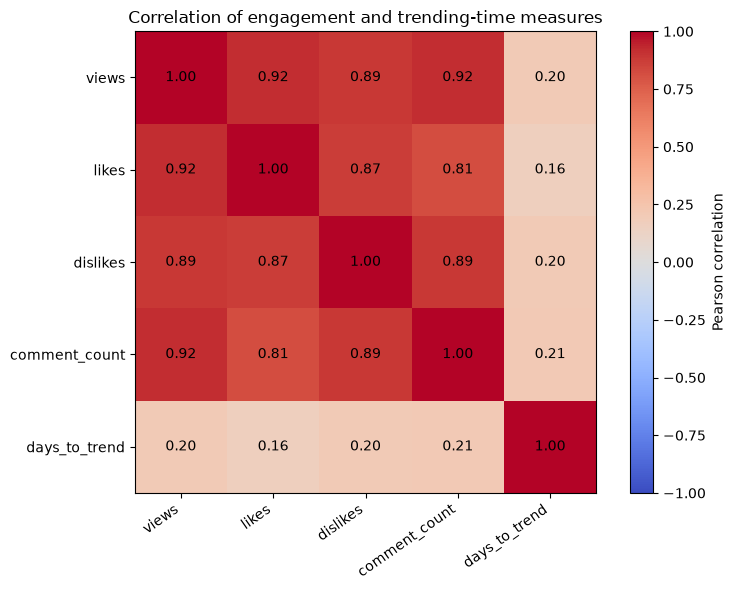

In [11]:
video_data["trending_datetime"] = pd.to_datetime(
    video_data["trending_date"], format="%y.%d.%m"
)
video_data["publish_datetime"] = pd.to_datetime(
    video_data["publish_time"], utc=True
).dt.tz_localize(None)
video_data["days_to_trend"] = (
    video_data["trending_datetime"] - video_data["publish_datetime"].dt.normalize()
).dt.days

correlation_columns = [
    "views", "likes", "dislikes", "comment_count", "days_to_trend"
]
correlation_data = video_data[correlation_columns].dropna()
correlation_matrix = correlation_data.corr()
print(f"Complete records used for every correlation: {len(correlation_data):,}")
display(correlation_matrix.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_columns)))
ax.set_xticklabels(correlation_columns, rotation=35, ha="right")
ax.set_yticks(range(len(correlation_columns)))
ax.set_yticklabels(correlation_columns)
for row in range(len(correlation_columns)):
    for column in range(len(correlation_columns)):
        ax.text(
            column,
            row,
            f"{correlation_matrix.iloc[row, column]:.2f}",
            ha="center",
            va="center",
            color="black",
        )
ax.set_title("Correlation of engagement and trending-time measures")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout()
plt.show()

**Interpretation:** The two strongest off-diagonal correlations are views with likes (*r* = 0.921) and views with comment count (*r* = 0.916); both are strong positive associations, so higher-view records tend also to have more likes and comments. These correlations do not prove that likes cause views: popular videos may attract both, and the observational data do not establish which changed first or control for other influences.

## Funnel analysis

The funnel uses one row per unique `video_id` across the cleaned country datasets. For each video, peak views and peak comment count are the maximum observed across its records; percentile cutoffs are calculated from the unique-video peak views. Stage conversion is the percentage retained from the immediately preceding stage, and cumulative conversion is relative to all videos that ever trended.

In [10]:
unique_video_metrics = video_data.groupby("video_id").agg(
    peak_views=("views", "max"),
    peak_comments=("comment_count", "max"),
)
median_peak_views = unique_video_metrics["peak_views"].median()
p90_peak_views = unique_video_metrics["peak_views"].quantile(0.90)

funnel_stages = [
    ("Ever trended", unique_video_metrics),
    (
        "Peak views above median",
        unique_video_metrics.loc[
            unique_video_metrics["peak_views"] > median_peak_views
        ],
    ),
    (
        "Peak views above 90th percentile",
        unique_video_metrics.loc[
            unique_video_metrics["peak_views"] > p90_peak_views
        ],
    ),
    (
        "Above 90th percentile and 1,000+ comments",
        unique_video_metrics.loc[
            (unique_video_metrics["peak_views"] > p90_peak_views)
            & (unique_video_metrics["peak_comments"] >= 1000)
        ],
    ),
]

funnel_rows = []
previous_count = None
for stage, videos in funnel_stages:
    count = len(videos)
    funnel_rows.append(
        {
            "stage": stage,
            "videos": count,
            "conversion from previous (%)": (
                100 if previous_count is None else count / previous_count * 100
            ),
            "conversion from start (%)": count / len(unique_video_metrics) * 100,
            "drop from previous": (
                0 if previous_count is None else previous_count - count
            ),
        }
    )
    previous_count = count

funnel_summary = pd.DataFrame(funnel_rows).set_index("stage")
stage_transitions = funnel_summary.iloc[1:]
largest_drop_stage = stage_transitions["drop from previous"].idxmax()
largest_drop = int(funnel_summary.loc[largest_drop_stage, "drop from previous"])
sharpest_drop_stage = stage_transitions["conversion from previous (%)"].idxmin()
sharpest_drop = 100 - funnel_summary.loc[
    sharpest_drop_stage, "conversion from previous (%)"
]
print(f"Median peak views: {median_peak_views:,.0f}")
print(f"90th-percentile peak views: {p90_peak_views:,.1f}")
display(funnel_summary.round(2))
print(
    f"Largest count drop-off: {largest_drop:,} videos before "
    f"'{largest_drop_stage}'."
)
print(
    f"Sharpest proportional drop-off: {sharpest_drop:.2f}% before "
    f"'{sharpest_drop_stage}'."
)

Median peak views: 265,290
90th-percentile peak views: 1,646,844.8


,videos,conversion from previous (%),conversion from start (%),drop from previous
stage,,,,
Ever trended,14688,100.00,100.0,0
Peak views above median,7344,50.00,50.0,7344
Peak views above 90th percentile,1469,20.00,10.0,5875
"Above 90th percentile and 1,000+ comments",1440,98.03,9.8,29


Largest count drop-off: 7,344 videos before 'Peak views above median'.
Sharpest proportional drop-off: 80.00% before 'Peak views above 90th percentile'.


| Funnel stage | Videos | Conversion from previous | Conversion from start |
|---|---:|---:|---:|
| Ever trended | 14,688 | 100.00% | 100.00% |
| Peak views above median | 7,344 | 50.00% | 50.00% |
| Peak views above 90th percentile | 1,469 | 20.00% | 10.00% |
| Above 90th percentile and 1,000+ comments | 1,440 | 98.03% | 9.80% |

**Interpretation:** The largest drop by count occurs at the median-view threshold, where 7,344 of 14,688 videos (50%) do not advance; the sharpest proportional drop is the next stage, where 80% of above-median videos fall below the 90th-percentile cutoff. This reflects the funnel's progressively more selective reach thresholds, while the 1,000-comment requirement removes only 29 videos (about 2%) from the high-view group, suggesting most top-reach videos also accumulated substantial comments.

## Retention-style analysis: trending lifespan

A cohort is a unique `(country, video_id)` pair, since trending-list membership is country-specific. Day 1 is that pair's first observed trending date; retention on day N requires the video to appear on every calendar day from day 1 through day N. To avoid right-censoring, only cohorts whose first day leaves a full seven days in the dataset are included. Categories are compared using Music and News & Politics.

,eligible videos,day 2 retained (%),day 3 retained (%),day 5 retained (%),day 7 retained (%)
group,,,,,
All videos,14531,63.66,42.24,19.56,9.94
Music,1869,81.11,65.86,43.55,29.59
News & Politics,1353,40.95,16.33,3.84,0.96


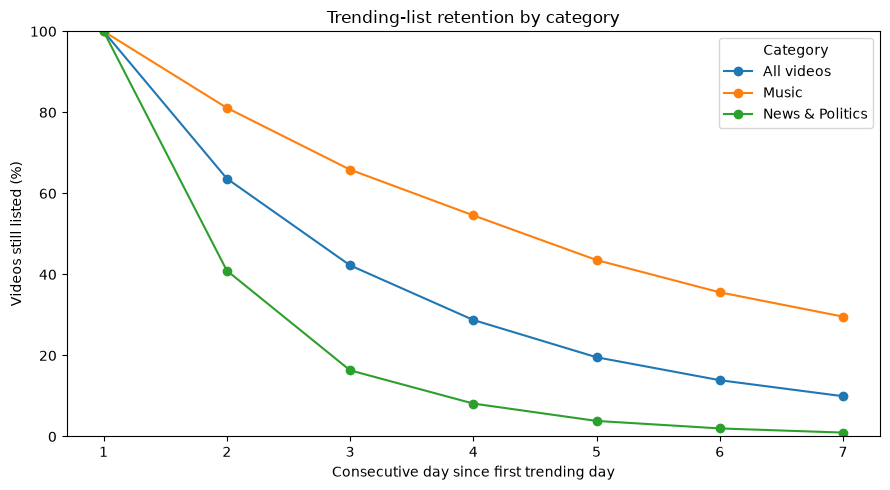

In [12]:
video_data["trending_datetime"] = pd.to_datetime(
    video_data["trending_date"], format="%y.%d.%m"
)
retention_cohorts = video_data.groupby(
    ["country", "video_id"], as_index=False
).agg(
    first_trending_day=("trending_datetime", "min"),
    category_name=("category_name", "first"),
)
last_trending_day = video_data["trending_datetime"].max()
retention_cohorts = retention_cohorts.loc[
    retention_cohorts["first_trending_day"]
    <= last_trending_day - pd.Timedelta(days=6)
].copy()
trending_records = set(
    zip(video_data["country"], video_data["video_id"], video_data["trending_datetime"])
)

for day_number in range(1, 8):
    retention_cohorts[f"day_{day_number}"] = [
        all(
            (
                cohort.country,
                cohort.video_id,
                cohort.first_trending_day + pd.Timedelta(days=elapsed_day),
            )
            in trending_records
            for elapsed_day in range(day_number)
        )
        for cohort in retention_cohorts.itertuples(index=False)
    ]

retention_groups = {
    "All videos": retention_cohorts,
    "Music": retention_cohorts.loc[
        retention_cohorts["category_name"] == "Music"
    ],
    "News & Politics": retention_cohorts.loc[
        retention_cohorts["category_name"] == "News & Politics"
    ],
}
reported_days = (2, 3, 5, 7)
retention_summary = pd.DataFrame(
    [
        {
            "group": group_name,
            "eligible videos": len(group),
            **{
                f"day {day} retained (%)": group[f"day_{day}"].mean() * 100
                for day in reported_days
            },
        }
        for group_name, group in retention_groups.items()
    ]
).set_index("group")
display(retention_summary.round(2))

retention_days = range(1, 8)
fig, ax = plt.subplots(figsize=(9, 5))
for group_name, group in retention_groups.items():
    retention_percentages = [
        group[f"day_{day}"].mean() * 100 for day in retention_days
    ]
    ax.plot(
        list(retention_days),
        retention_percentages,
        marker="o",
        label=group_name,
    )
ax.set_xticks(list(retention_days))
ax.set_ylim(0, 100)
ax.set_title("Trending-list retention by category")
ax.set_xlabel("Consecutive day since first trending day")
ax.set_ylabel("Videos still listed (%)")
ax.legend(title="Category")
fig.tight_layout()
plt.show()

| Group | Eligible video-country pairs | Day 2 | Day 3 | Day 5 | Day 7 |
|---|---:|---:|---:|---:|---:|
| All videos | 14,531 | 63.66% | 42.24% | 19.56% | 9.94% |
| Music | 1,869 | 81.11% | 65.86% | 43.55% | 29.59% |
| News & Politics | 1,353 | 40.95% | 16.33% | 3.84% | 0.96% |

**Interpretation:** Of 14,531 eligible video-country cohorts, 63.66% remained listed on day 2, 42.24% on day 3, 19.56% on day 5, and 9.94% on day 7. Music videos persisted longer than News & Politics videos: 81.11% versus 40.95% reached day 2, and 29.59% versus 0.96% lasted through day 7. Thus, News & Politics videos were much more likely to disappear after their first day, while Music videos were more likely to stay on the list.

## Cohort view

Each cohort is a calendar week (Monday–Sunday) in which a unique video-country pair first trended. The comparison metric is median views on that first trending record; cohort size is shown alongside it to reveal weeks with less data.

,video_country_pairs,median_first_day_views
cohort_week,,
2017-11-13,1607,186401.0
2017-11-20,1326,190628.0
2017-11-27,1318,183318.0
2017-12-04,1323,188984.0
2017-12-11,1327,203081.0
2017-12-18,1375,178508.0
2017-12-25,1297,188960.0
2018-01-01,1349,179530.0
2018-01-08,1356,196872.0


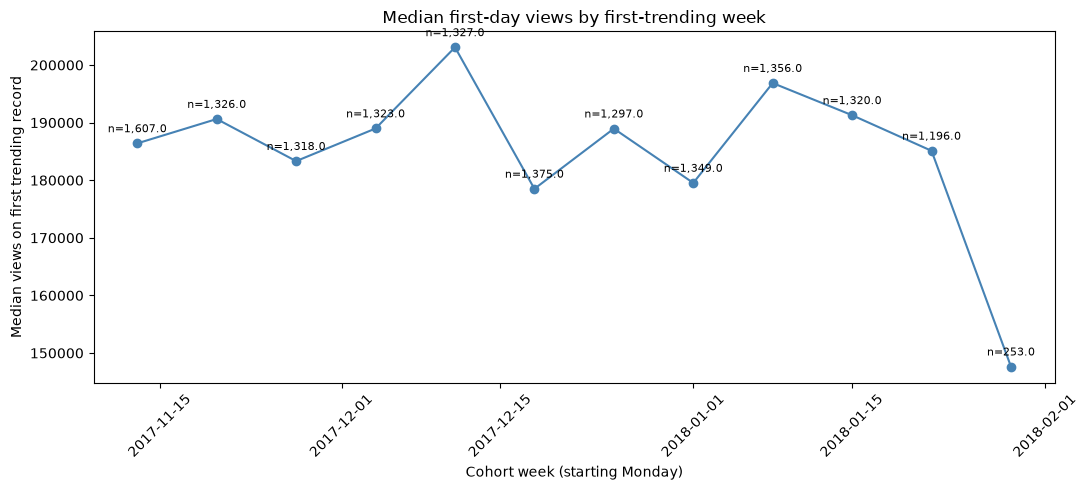

In [13]:
video_data["trending_datetime"] = pd.to_datetime(
    video_data["trending_date"], format="%y.%d.%m"
)
cohort_first_records = (
    video_data.sort_values(
        ["country", "video_id", "trending_datetime"]
    )
    .drop_duplicates(["country", "video_id"], keep="first")
    .copy()
)
cohort_first_records["cohort_week"] = (
    cohort_first_records["trending_datetime"]
    .dt.to_period("W-SUN")
    .dt.start_time
)
weekly_cohorts = cohort_first_records.groupby("cohort_week").agg(
    video_country_pairs=("video_id", "size"),
    median_first_day_views=("views", "median"),
)
display(weekly_cohorts.round(0))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    weekly_cohorts.index,
    weekly_cohorts["median_first_day_views"],
    marker="o",
    color="steelblue",
)
for week, row in weekly_cohorts.iterrows():
    ax.annotate(
        f"n={row['video_country_pairs']:,}",
        (week, row["median_first_day_views"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )
ax.set_title("Median first-day views by first-trending week")
ax.set_xlabel("Cohort week (starting Monday)")
ax.set_ylabel("Median views on first trending record")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

**Interpretation:** Across the complete weeks, median first-day views are fairly similar, ranging from 178,508 to 203,081 for cohorts of 1,196–1,607 video-country pairs. The final week (January 29) is lower at 147,637, but it has only 253 pairs and the dataset ends on February 1, so that partial week's smaller sample could explain the difference; treat it as provisional rather than a clear cohort shift.

## Content strategy briefing

Entertainment and Music dominate the cleaned dataset by trending-record count, with 12,244 and 10,286 records respectively. Videos reach the trending list quickly: the median time from publication to a trending record is 3 days, and 55.3% of records trend within 3 days. Persistence differs by category: 81.11% of Music video-country cohorts remain through day 2 and 29.59% through day 7, compared with 40.95% and 0.96% for News & Politics, so Music is more likely to stay while News & Politics often disappears after day 1. Views also vary by country: the mean per trending record is about 1.58 million in GB, 1.01 million in the US, and 0.95 million in IN, while the median is highest in IN at about 356,131, showing that a few very high-view records lift the means. These results cover only videos that appeared on trending lists in the fixed November 14, 2017–February 1, 2018 window, so they cannot explain why other videos never trended or establish that the same patterns hold outside this period.

## Chart basics

The following Matplotlib charts show categorical counts, distributions, relationships, and changes over time. The scatter plot uses a reproducible sample for readability; the other charts use the full cleaned dataset.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("default")

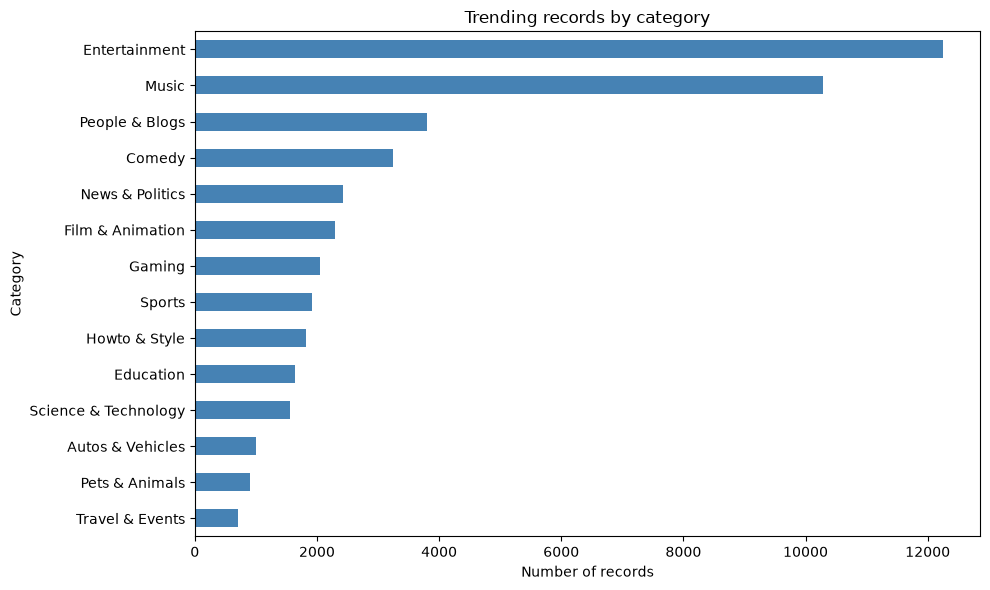

In [3]:
category_counts = video_data["category_name"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
category_counts.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Trending records by category")
ax.set_xlabel("Number of records")
ax.set_ylabel("Category")
fig.tight_layout()
plt.show()

**Interpretation:** Entertainment has the most trending records (12,244), followed by Music (10,286), while Travel & Events has the fewest (708). These are record counts, so a video that trended on multiple dates can contribute more than once. A horizontal bar chart fits because it compares counts across categorical groups and keeps the category labels readable.

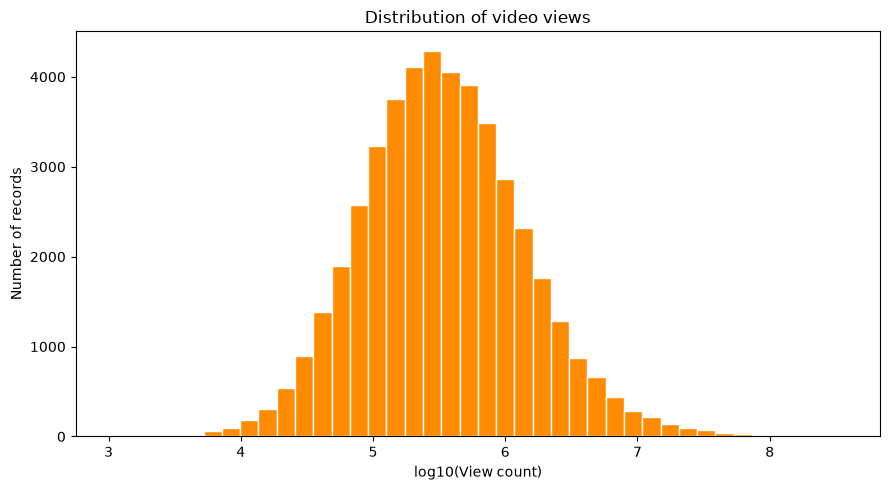

In [4]:
log_views = np.log10(video_data.loc[video_data["views"] > 0, "views"])
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(log_views, bins=40, color="darkorange", edgecolor="white")
ax.set_title("Distribution of video views")
ax.set_xlabel("log10(View count)")
ax.set_ylabel("Number of records")
fig.tight_layout()
plt.show()

**Interpretation:** Views are strongly right-skewed: about 79% of records have at most one million views, while the top 1% exceed roughly 14 million. The log-scaled horizontal axis makes the broad range of positive view counts easier to inspect. A histogram fits because views are numerical and it shows how frequently values occur within ranges.

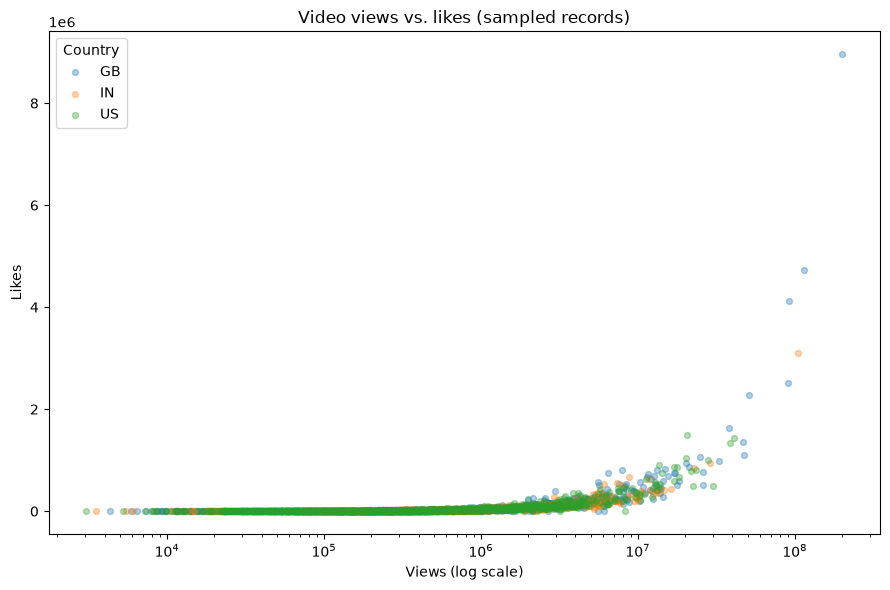

In [5]:
scatter_data = video_data[["views", "likes", "country"]].dropna(subset=["views", "likes"])
scatter_data = scatter_data.sample(n=min(6000, len(scatter_data)), random_state=42)
fig, ax = plt.subplots(figsize=(9, 6))
for country, country_data in scatter_data.groupby("country"):
    ax.scatter(
        country_data["views"],
        country_data["likes"],
        alpha=0.35,
        s=18,
        label=country,
    )
ax.set_xscale("log")
ax.set_title("Video views vs. likes (sampled records)")
ax.set_xlabel("Views (log scale)")
ax.set_ylabel("Likes")
ax.legend(title="Country")
fig.tight_layout()
plt.show()

**Interpretation:** In the reproducible sample, views and likes have a strong positive association: videos with more views generally also have more likes. The country-colored points show this relationship across GB, IN, and US, with considerable variation among videos at similar view counts. A scatter plot fits because both views and likes are numerical variables and the points reveal their relationship.

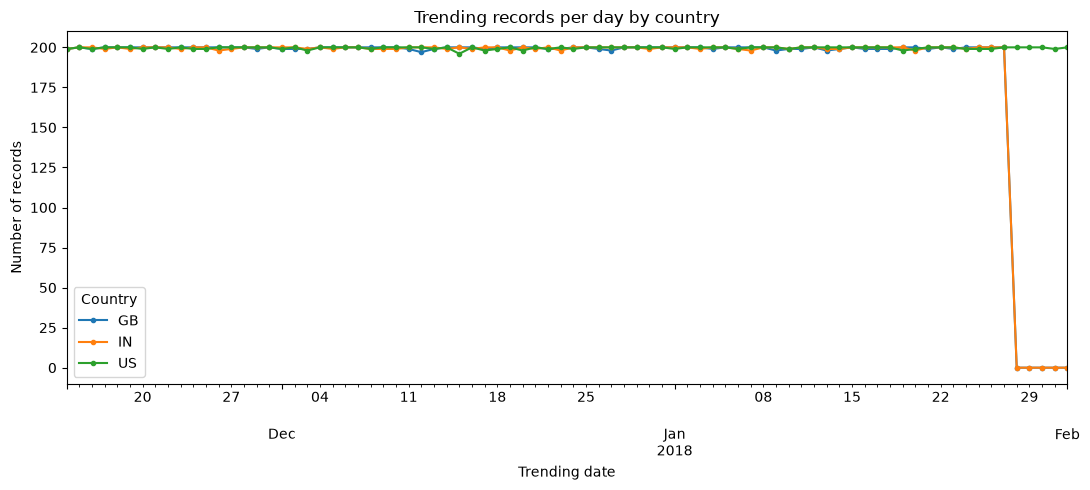

In [6]:
dated_data = video_data.assign(
    trending_datetime=pd.to_datetime(video_data["trending_date"], format="%y.%d.%m")
)
daily_counts = dated_data.groupby(["trending_datetime", "country"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 5))
daily_counts.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Trending records per day by country")
ax.set_xlabel("Trending date")
ax.set_ylabel("Number of records")
ax.legend(title="Country")
fig.tight_layout()
plt.show()

**Interpretation:** The lines show how many trending records appear per day in each country, and all three reach 200 records on November 15, 2017. Their day-to-day counts can be compared over the same timeline. A line chart fits because the date is ordered and connecting points makes temporal changes visible.

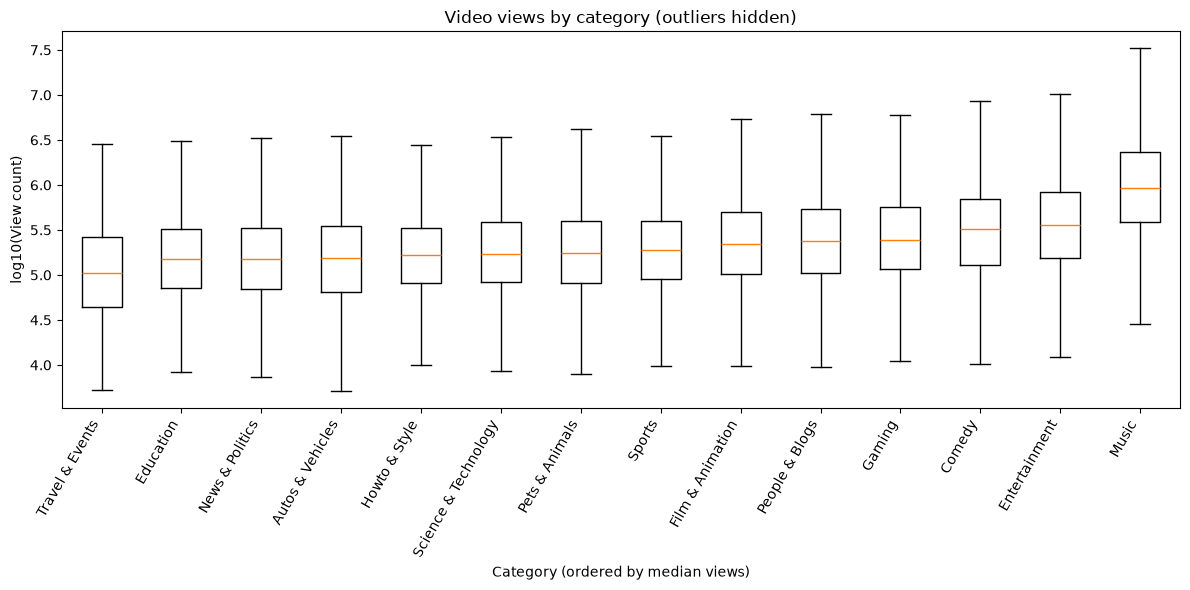

In [7]:
category_order = (
    video_data.groupby("category_name")["views"]
    .median()
    .sort_values()
    .index
)
boxplot_data = [
    np.log10(video_data.loc[video_data["category_name"] == category, "views"].clip(lower=1))
    for category in category_order
]
fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot(boxplot_data, showfliers=False)
ax.set_xticks(range(1, len(category_order) + 1))
ax.set_xticklabels(category_order, rotation=60, ha="right")
ax.set_title("Video views by category (outliers hidden)")
ax.set_xlabel("Category (ordered by median views)")
ax.set_ylabel("log10(View count)")
fig.tight_layout()
plt.show()

**Interpretation:** Median views differ across categories: Music has the highest median, while Travel & Events has the lowest. The distributions also vary within categories; outlier markers are hidden, and the vertical axis uses log10 views. A boxplot fits because it summarizes and compares the distribution of a numerical variable across categorical groups.

## Interactive charts

The Plotly charts below use the cleaned combined dataset. The scatter plot is sampled for readability and shows each video's title on hover; the grouped bar chart compares mean trending-record views by category across countries.

In [8]:
import plotly.express as px

plotly_scatter_data = video_data[
    ["title", "category_name", "country", "views", "likes"]
].dropna(subset=["views", "likes"])
plotly_scatter_data = plotly_scatter_data.sample(
    n=min(8000, len(plotly_scatter_data)), random_state=42
)

scatter_fig = px.scatter(
    plotly_scatter_data,
    x="views",
    y="likes",
    color="category_name",
    hover_name="title",
    hover_data={"country": True, "views": ":,", "likes": ":,"},
    render_mode="webgl",
    opacity=0.65,
    title="Video views vs. likes by category (sampled records)",
)
scatter_fig.update_layout(
    xaxis_title="Views",
    yaxis_title="Likes",
    legend_title_text="Category",
)
scatter_fig.show()

**Interpretation:** In the sampled records, likes generally increase with views, while a relatively small number of videos reach especially high view and like counts. The category colors and hover labels make it possible to explore individual videos and compare category patterns. A scatter plot fits because views and likes are both numerical variables, and it reveals their relationship while color distinguishes categories.

In [9]:
category_country_views = (
    video_data.groupby(["category_name", "country"], as_index=False)["views"]
    .mean()
)

category_country_fig = px.bar(
    category_country_views,
    x="category_name",
    y="views",
    color="country",
    barmode="group",
    hover_data={"views": ":,"},
    title="Average views per trending record by category and country",
    labels={
        "category_name": "Category",
        "views": "Average views",
        "country": "Country",
    },
)
category_country_fig.update_layout(xaxis_tickangle=-45)
category_country_fig.show()

**Interpretation:** Average views vary substantially across category-country combinations, with Music among the highest-mean categories overall. Within each category, the grouped bars make differences between GB, IN, and US easy to compare. A grouped bar chart fits because it compares one numerical summary (mean views) across two categorical variables (category and country).